In [1]:
# Agentic AI & Multi-Agent Network Operations

In [2]:
from __future__ import annotations

import hashlib
import operator
import importlib.metadata as metadata
import json
import math
import os
import platform
import re
import sqlite3
import tempfile
import time
import uuid
from dataclasses import dataclass
from datetime import datetime, timedelta, timezone
from pathlib import Path
from typing import Annotated, Any, Callable, Literal, TypedDict

import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from pydantic import BaseModel, ConfigDict, Field, ValidationError, model_validator
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 120)
RANDOM_STATE = 42

print("Python:", platform.python_version())
print("Platform:", platform.platform())

Python: 3.12.13
Platform: macOS-27.0.1-arm64-arm-64bit


In [3]:
def show_langgraph_figure(compiled_graph, title: str) -> None:
    '''Display a compiled LangGraph as a Mermaid PNG, with a safe text fallback.'''
    print(f"\n{title}")
    try:
        # User-requested visualization pattern:
        display(Image(compiled_graph.get_graph().draw_mermaid_png()))
    except Exception as exc:
        print(f"PNG rendering unavailable ({type(exc).__name__}). Mermaid source follows:")
        print(compiled_graph.get_graph().draw_mermaid())

In [4]:
EXPECTED = {
    "numpy": "2.5.2",
    "pandas": "3.0.5",
    "scikit-learn": "1.9.0",
    "pydantic": "2.13.4",
    "networkx": "3.6.1",
    "openai": "3.3.1",
    "openai-agents": "0.22.0",
    "langgraph": "1.2.11",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.3.0",
}
installed = {name: metadata.version(name) for name in EXPECTED}
version_check = pd.DataFrame(
    [
        {
            "package": name,
            "expected": expected,
            "installed": installed[name],
            "match": installed[name] == expected,
        }
        for name, expected in EXPECTED.items()
    ]
)
display(version_check)
assert tuple(map(int, platform.python_version_tuple()[:2])) >= (3, 12)
assert version_check["match"].all(), "Install the exact Session 4 requirements before continuing."
print("✓ Runtime matches the tested package set")

,package,expected,installed,match
0,numpy,2.5.2,2.5.2,True
1,pandas,3.0.5,3.0.5,True
2,scikit-learn,1.9.0,1.9.0,True
3,pydantic,2.13.4,2.13.4,True
4,networkx,3.6.1,3.6.1,True
5,openai,3.3.1,3.3.1,True
6,openai-agents,0.22.0,0.22.0,True
7,langgraph,1.2.11,1.2.11,True
8,nbformat,5.11.1,5.11.1,True
9,nbclient,0.11.0,0.11.0,True


✓ Runtime matches the tested package set


In [5]:
def locate_artifact(filename: str) -> Path:
    candidates = [
        Path.cwd() / filename,
        Path.cwd() / "outputs" / filename,
        Path.cwd().parent / "outputs" / filename,
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(f"Could not find {filename}. Checked: {candidates}")

CORPUS_PATH = locate_artifact("session3_walmart_network_corpus.jsonl")
MANIFEST_PATH = locate_artifact("session3_source_manifest.json")
records = [json.loads(line) for line in CORPUS_PATH.read_text().splitlines() if line.strip()]
manifest = json.loads(MANIFEST_PATH.read_text())

assert hashlib.sha256(CORPUS_PATH.read_bytes()).hexdigest() == manifest["corpus_sha256"]
assert len(records) == manifest["record_count"]
print(manifest["provenance_statement"])
print(f"✓ Loaded {len(records)} verified public records")

All operational facts and examples are sourced from public Walmart Global Tech or Walmart-originated L3AF project materials. No internal Walmart runbook, configuration, incident, topology, monitoring record, credential, or production state is claimed or fabricated.
✓ Loaded 81 verified public records


In [6]:
corpus_df = pd.DataFrame(records)
display(
    corpus_df.groupby("source_type", as_index=False)
    .agg(records=("doc_id", "count"), example=("title", "first"))
    .sort_values("records", ascending=False)
)

search_texts = (corpus_df["title"] + " " + corpus_df["content"]).tolist()
vectorizer = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), sublinear_tf=True)
corpus_matrix = vectorizer.fit_transform(search_texts)

def search_corpus(query: str, top_k: int = 5, source_types: set[str] | None = None) -> list[dict[str, Any]]:
    if not query.strip():
        raise ValueError("query must not be empty")
    scores = cosine_similarity(vectorizer.transform([query]), corpus_matrix).ravel()
    mask = np.ones(len(corpus_df), dtype=bool)
    if source_types:
        mask = corpus_df["source_type"].isin(source_types).to_numpy()
    candidates = np.where(mask)[0]
    ranked = candidates[np.argsort(scores[candidates])[::-1]][:top_k]
    return [
        {
            **corpus_df.iloc[i].to_dict(),
            "score": float(scores[i]),
        }
        for i in ranked
    ]

display(pd.DataFrame(search_corpus("BPFRunning metric loading error", 3))[["doc_id", "score", "title", "source_url"]])

,source_type,records,example
4,historical_issue,37,L3AFD issue #754: Build failure on Cilium eBPF package upgrade
3,configuration_standard,12,configdoc: L3AFD Config Options Documentation
2,configuration_repository,10,l3afd sample configuration: [l3afd]
9,project_readme,9,README: L3AFD: Lightweight eBPF Daemon
6,operational_runbook,5,graceful-restart-guide: Prerequisites
8,production_deployment_guide,3,prod-deploy-guide: Installing l3afd
7,package_repository_guide,2,README: eBPF Package Repository
0,api_specification,1,l3afd REST API operation inventory
1,change_records,1,L3AFD recent public commit history
5,official_walmart_global_tech_article,1,Walmart Global Tech: published network scale and open-source context


,doc_id,score,title,source_url
0,l3afd-issue-698,0.295954,L3AFD issue #698: l3afd_BPFRunning metric reports true incase of ebpf_program loading error,https://github.com/l3af-project/l3afd/issues/698
1,l3afd-issue-523,0.129092,L3AFD issue #523: Add metrics to count ebpf program loading failure errors,https://github.com/l3af-project/l3afd/issues/523
2,l3afd-issue-637,0.080799,L3AFD issue #637: Remove stale metric reporting on eBPF program unload,https://github.com/l3af-project/l3afd/issues/637


## LangGraph from first principles

LangGraph is an orchestration framework for long-running, stateful workflows and agents. It does not magically make an LLM autonomous. It gives engineers explicit control over **what can happen next**.

Think of a network troubleshooting workflow as a controlled packet journey:

| LangGraph concept | Plain meaning | Infrastructure analogy |
|---|---|---|
| State | Shared typed record carried through the workflow | Incident record containing evidence, status and approvals |
| Node | A Python function that reads state and returns updates | Monitoring query, configuration check or RCA step |
| Edge | An allowed transition between nodes | Runbook transition from evidence collection to validation |
| Conditional edge | Runtime routing decision | If severity is critical, escalate; otherwise continue diagnosis |
| Loop | Revisit a node until a stopping condition holds | Poll telemetry until enough samples arrive or the budget expires |
| Checkpointer | Saves thread-scoped state after steps | Incident checkpoint used to resume after a pause or failure |
| Interrupt | Pauses execution for external input | Human approval before a controlled action |
| Command | Resumes or redirects execution | Approval response that continues the saved workflow |

The engineering sequence is always the same:

**Define state → write small nodes → connect edges → compile → invoke with input → inspect final state**

Why use a graph instead of a large `while` loop? The graph makes legal transitions, branches, cycles, checkpoints and human gates visible and testable. Business policy still belongs in deterministic code; the model may assist with semantic decisions inside those boundaries.

### Example A — Linear shared-state flow

A linear graph is the easiest mental model: intake receives an incident, normalization creates a consistent representation, and summary produces the handoff. Every node receives the same state schema and returns only its updates.

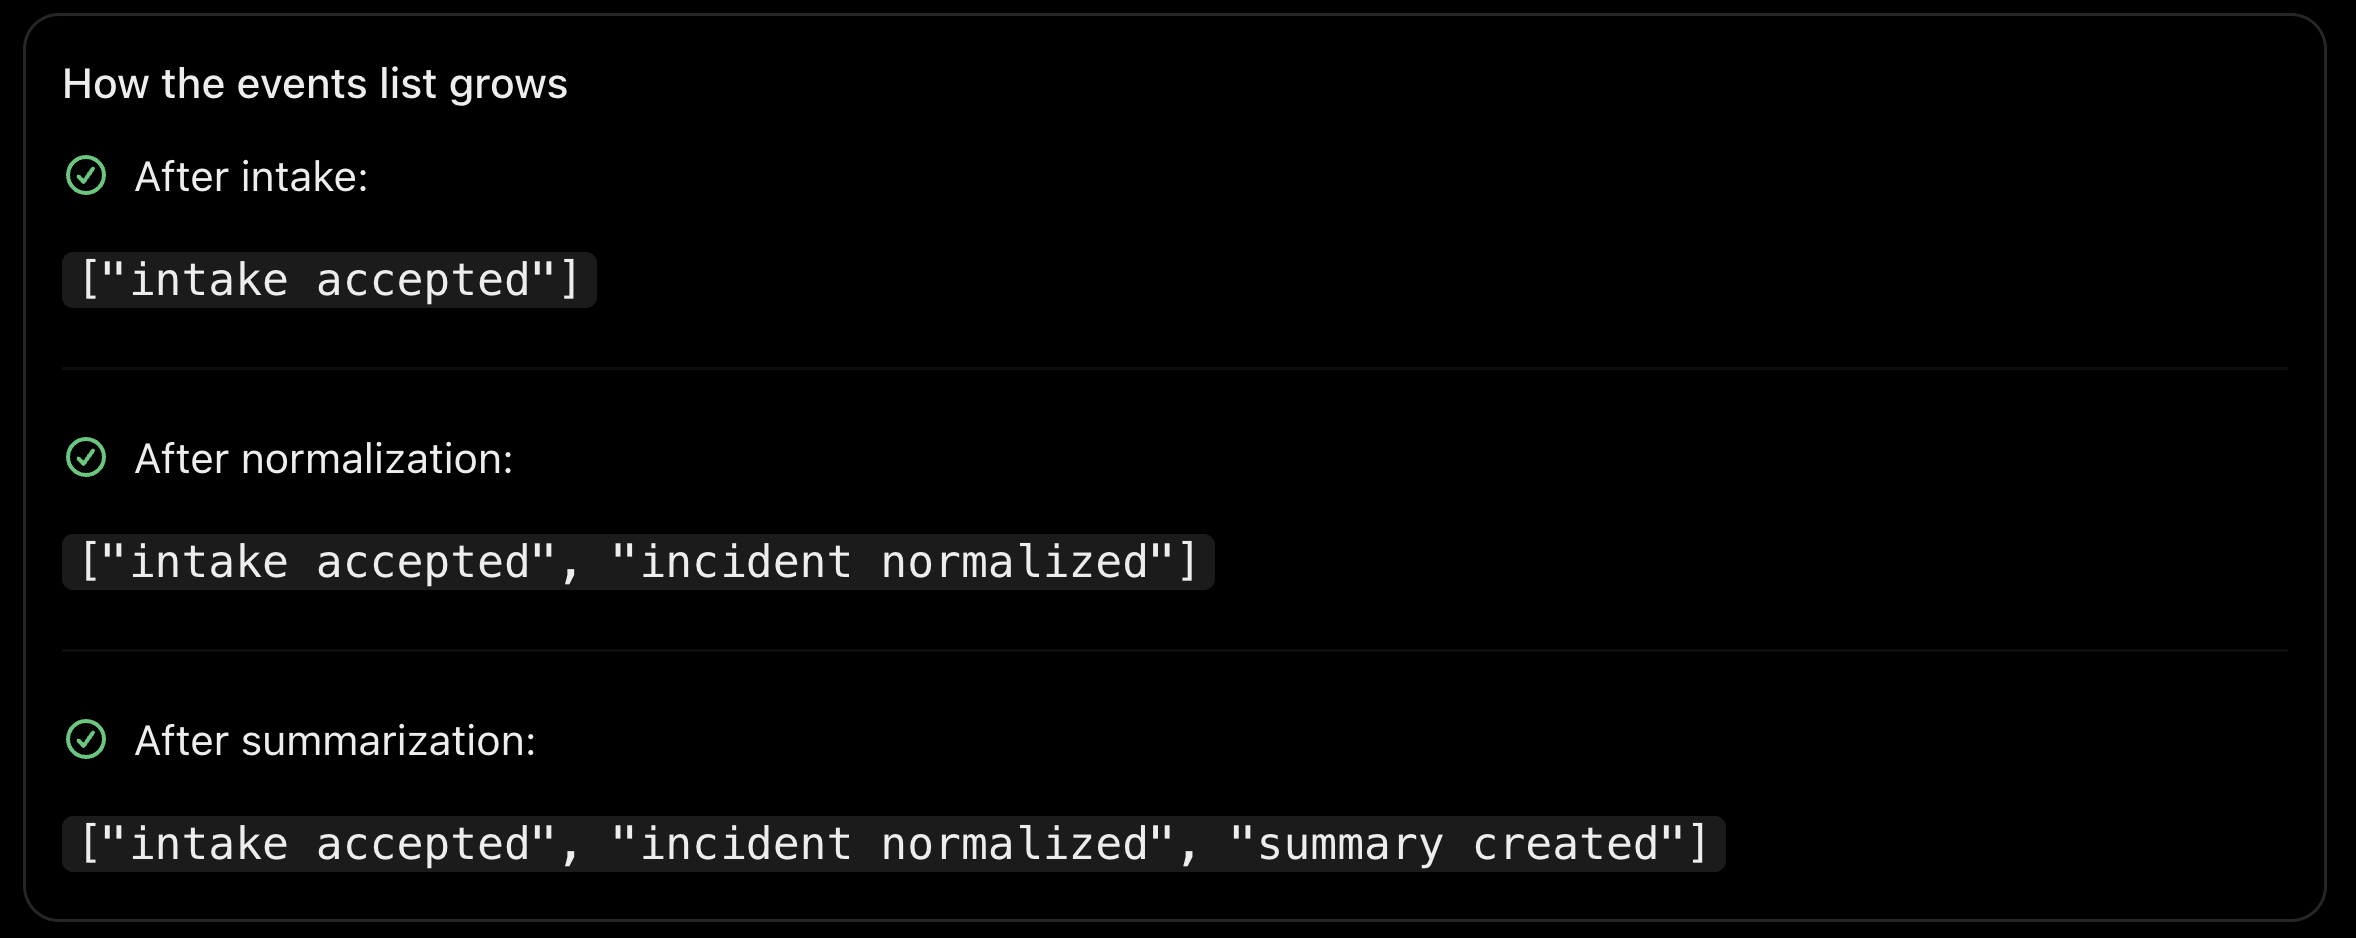

,input,normalized,summary,node_outputs
0,DC-07 inventory API is intermittently unreachable,dc-07 inventory api is intermittently unreachable,Network incident received: dc-07 inventory api is intermittently unreachable,intake accepted → incident normalized → summary created
1,STORE-1842 access point reports high channel utilization,store-1842 access point reports high channel utilization,Network incident received: store-1842 access point reports high channel utilization,intake accepted → incident normalized → summary created
2,Cloud load balancer health checks are timing out,cloud load balancer health checks are timing out,Network incident received: cloud load balancer health checks are timing out,intake accepted → incident normalized → summary created



Figure A — Linear intake workflow


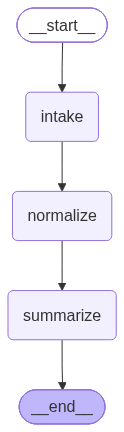

In [ ]:
class LinearState(TypedDict):
    incident: str
    normalized: str
    summary: str
    events: Annotated[list[str], operator.add]
# events: Annotated[list[str], operator.add]
# Normally, returning a new value for a state key replaces the existing value.
# However, we want to keep adding events instead of overwriting previous events.
# For example:


def linear_intake(state: LinearState) -> dict:
    return {"events": ["intake accepted"]}

def linear_normalize(state: LinearState) -> dict: # "  DC-07 inventory API is intermittently unreachable  "
    normalized = re.sub(r"\s+", " ", state["incident"].strip()).lower() # "dc-07 inventory api is intermittently unreachable"
    return {"normalized": normalized, "events": ["incident normalized"]}

def linear_summarize(state: LinearState) -> dict:
    return {
        "summary": f"Network incident received: {state['normalized']}",
        "events": ["summary created"],
    }

linear_builder = StateGraph(LinearState)
linear_builder.add_node("intake", linear_intake)
linear_builder.add_node("normalize", linear_normalize)
linear_builder.add_node("summarize", linear_summarize)
linear_builder.add_edge(START, "intake")
linear_builder.add_edge("intake", "normalize")
linear_builder.add_edge("normalize", "summarize")
linear_builder.add_edge("summarize", END)
linear_graph = linear_builder.compile()

linear_examples = [
    "  DC-07 inventory API is intermittently unreachable  ",
    "STORE-1842 access point reports high channel utilization",
    "Cloud load balancer health checks are timing out",
]
linear_results = []
for example in linear_examples: # example= "  DC-07 inventory API is intermittently unreachable  "
    result = linear_graph.invoke({
        "incident":example, "normalized":"", "summary":"", "events":[],
    })
    linear_results.append({
        "input":example.strip(), "normalized":result["normalized"],
        "summary":result["summary"], "node_outputs":" → ".join(result["events"]),
    })

display(pd.DataFrame(linear_results))
show_langgraph_figure(linear_graph, "Figure A — Linear intake workflow")
assert all(row["node_outputs"].endswith("summary created") for row in linear_results)

### Example B — Conditional branch

A branch represents an explicit operating decision. Here the classifier is deterministic and auditable: critical incidents follow an urgent path; other incidents follow the standard path. In production the model may propose severity, but policy validates it before routing.

,severity,route,response,events
0,SEV1,urgent,Open incident bridge and page the on-call lead.,classified as urgent → urgent path
1,SEV2,standard,Queue bounded diagnostic collection.,classified as standard → standard path
2,SEV3,standard,Queue bounded diagnostic collection.,classified as standard → standard path



Figure B — Conditional severity branch


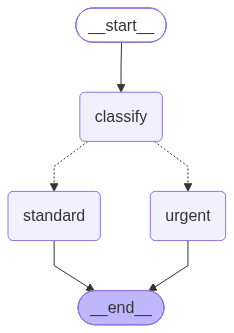

In [8]:
class BranchState(TypedDict):
    severity: str
    route: str
    response: str
    events: Annotated[list[str], operator.add]

def classify_severity(state: BranchState) -> dict:
    route = "urgent" if state["severity"].upper() in {"SEV0", "SEV1"} else "standard"
    return {"route": route, "events": [f"classified as {route}"]}

def urgent_path(state: BranchState) -> dict:
    return {"response": "Open incident bridge and page the on-call lead.", "events": ["urgent path"]}

def standard_path(state: BranchState) -> dict:
    return {"response": "Queue bounded diagnostic collection.", "events": ["standard path"]}

branch_builder = StateGraph(BranchState)
branch_builder.add_node("classify", classify_severity)
branch_builder.add_node("urgent", urgent_path)
branch_builder.add_node("standard", standard_path)
branch_builder.add_edge(START, "classify")
branch_builder.add_conditional_edges("classify", lambda s: s["route"], {"urgent":"urgent", "standard":"standard"})
branch_builder.add_edge("urgent", END)
branch_builder.add_edge("standard", END)
branch_graph = branch_builder.compile()

branch_results = []
for severity in ["SEV1", "SEV2", "SEV3"]:
    result = branch_graph.invoke({"severity":severity, "route":"", "response":"", "events":[]})
    branch_results.append({"severity":severity, "route":result["route"],
                           "response":result["response"], "events":" → ".join(result["events"])})

display(pd.DataFrame(branch_results))
show_langgraph_figure(branch_graph, "Figure B — Conditional severity branch")
assert {row["route"] for row in branch_results} == {"urgent", "standard"}

### Example C — Bounded loop

Agents often need another observation. A safe loop has a measurable completion condition and a hard budget. This example collects at most three samples; it cannot poll forever.

,max_attempts,actual_attempts,samples,enough_evidence,stop_reason
0,2,2,"[95, 90]",False,attempt budget exhausted
1,3,3,"[95, 90, 85]",True,three samples collected
2,5,3,"[95, 90, 85]",True,three samples collected



Figure C — Bounded evidence-collection loop


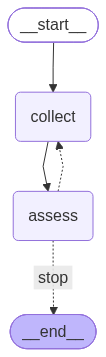

In [9]:
class LoopState(TypedDict):
    attempts: int
    max_attempts: int
    samples: Annotated[list[int], operator.add]
    enough_evidence: bool
    stop_reason: str

def collect_sample(state: LoopState) -> dict:
    next_attempt = state["attempts"] + 1
    return {"attempts": next_attempt, "samples": [100 - 5 * next_attempt]}

def assess_samples(state: LoopState) -> dict:
    enough = len(state["samples"]) >= 3
    exhausted = state["attempts"] >= state["max_attempts"]
    reason = "three samples collected" if enough else ("attempt budget exhausted" if exhausted else "need another sample")
    return {"enough_evidence": enough, "stop_reason": reason}

def route_loop(state: LoopState) -> str:
    return "stop" if state["enough_evidence"] or state["attempts"] >= state["max_attempts"] else "collect"

loop_builder = StateGraph(LoopState)
loop_builder.add_node("collect", collect_sample)
loop_builder.add_node("assess", assess_samples)
loop_builder.add_edge(START, "collect")
loop_builder.add_edge("collect", "assess")
loop_builder.add_conditional_edges("assess", route_loop, {"collect":"collect", "stop":END})
loop_graph = loop_builder.compile()

loop_results = []
for max_attempts in [2, 3, 5]:
    result = loop_graph.invoke(
        {"attempts":0, "max_attempts":max_attempts, "samples":[],
         "enough_evidence":False, "stop_reason":""},
        config={"recursion_limit":20},
    )
    loop_results.append({"max_attempts":max_attempts, "actual_attempts":result["attempts"],
                         "samples":result["samples"], "enough_evidence":result["enough_evidence"],
                         "stop_reason":result["stop_reason"]})

display(pd.DataFrame(loop_results))
show_langgraph_figure(loop_graph, "Figure C — Bounded evidence-collection loop")
assert loop_results[0]["stop_reason"] == "attempt budget exhausted"
assert loop_results[1]["enough_evidence"] and loop_results[2]["actual_attempts"] == 3

### Example D — Human-in-the-loop interrupt and resume

LangGraph `interrupt()` pauses a node and stores the thread state through a checkpointer. The application displays the JSON-safe approval request. The same `thread_id` is then resumed with `Command(resume=...)`. Code before an interrupt can execute again after resumption, so side effects must occur only after approval and must be idempotent.

,action,requested_approval,interrupt_payload,final_status,events
0,validate a route-policy dry run,True,"{'question': 'Approve dry-run validation?', 'action': 'validate a route-policy dry run'}",DRY_RUN_COMPLETE,proposal created → human decision received → dry-run executed
1,restart a production edge router,False,"{'question': 'Approve dry-run validation?', 'action': 'restart a production edge router'}",CANCELLED,proposal created → human decision received → request cancelled



Figure D — Human approval interrupt and resume


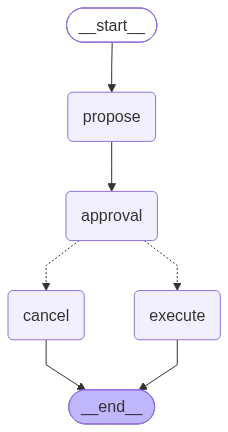

In [10]:
class IntroApprovalState(TypedDict):
    action: str
    approved: bool | None
    status: str
    events: Annotated[list[str], operator.add]

def propose_action(state: IntroApprovalState) -> dict:
    return {"status":"PENDING_APPROVAL", "events":["proposal created"]}

def request_intro_approval(state: IntroApprovalState) -> dict:
    response = interrupt({"question":"Approve dry-run validation?", "action":state["action"]})
    return {"approved":bool(response.get("approved", False)), "events":["human decision received"]}

def intro_execute(state: IntroApprovalState) -> dict:
    return {"status":"DRY_RUN_COMPLETE", "events":["dry-run executed"]}

def intro_cancel(state: IntroApprovalState) -> dict:
    return {"status":"CANCELLED", "events":["request cancelled"]}

intro_builder = StateGraph(IntroApprovalState)
intro_builder.add_node("propose", propose_action)
intro_builder.add_node("approval", request_intro_approval)
intro_builder.add_node("execute", intro_execute)
intro_builder.add_node("cancel", intro_cancel)
intro_builder.add_edge(START, "propose")
intro_builder.add_edge("propose", "approval")
intro_builder.add_conditional_edges("approval", lambda s: "execute" if s["approved"] else "cancel", {"execute":"execute", "cancel":"cancel"})
intro_builder.add_edge("execute", END)
intro_builder.add_edge("cancel", END)
intro_graph = intro_builder.compile(checkpointer=InMemorySaver())

def run_intro_approval_example(thread_id: str, action: str, approve: bool) -> dict:
    config = {"configurable":{"thread_id":thread_id}}
    paused = intro_graph.invoke(
        {"action":action, "approved":None, "status":"NEW", "events":[]}, config=config,
    )
    payload = paused["__interrupt__"][0].value
    resumed = intro_graph.invoke(Command(resume={"approved":approve}), config=config)
    return {"action":action, "requested_approval":approve, "interrupt_payload":payload,
            "final_status":resumed["status"], "events":" → ".join(resumed["events"])}

intro_results = [
    run_intro_approval_example("day4-intro-approve", "validate a route-policy dry run", True),
    run_intro_approval_example("day4-intro-reject", "restart a production edge router", False),
]
display(pd.DataFrame(intro_results))
show_langgraph_figure(intro_graph, "Figure D — Human approval interrupt and resume")
assert [row["final_status"] for row in intro_results] == ["DRY_RUN_COMPLETE", "CANCELLED"]

,action,requested_approval,interrupt_payload,final_status,events
0,validate a route-policy dry run,True,"{'question': 'Approve dry-run validation?', 'action': 'validate a route-policy dry run'}",DRY_RUN_COMPLETE,proposal created → human decision received → dry-run executed
1,restart a production edge router,False,"{'question': 'Approve dry-run validation?', 'action': 'restart a production edge router'}",CANCELLED,proposal created → human decision received → request cancelled



Figure D — Human approval interrupt and resume


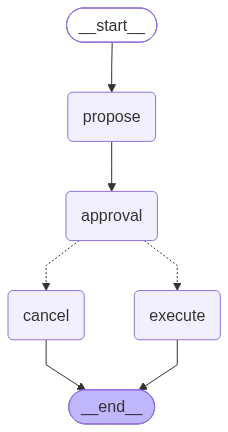

In [13]:
class IntroApprovalState(TypedDict):
    action: str
    approved: bool | None
    status: str
    events: Annotated[list[str], operator.add]

def propose_action(state: IntroApprovalState) -> dict:
    return {"status":"PENDING_APPROVAL", "events":["proposal created"]}

def request_intro_approval(state: IntroApprovalState) -> dict:
    response = interrupt({"question":"Approve dry-run validation?", "action":state["action"]})
    return {"approved":bool(response.get("approved", False)), "events":["human decision received"]}

def intro_execute(state: IntroApprovalState) -> dict:
    return {"status":"DRY_RUN_COMPLETE", "events":["dry-run executed"]}

def intro_cancel(state: IntroApprovalState) -> dict:
    return {"status":"CANCELLED", "events":["request cancelled"]}

intro_builder = StateGraph(IntroApprovalState)
intro_builder.add_node("propose", propose_action)
intro_builder.add_node("approval", request_intro_approval)
intro_builder.add_node("execute", intro_execute)
intro_builder.add_node("cancel", intro_cancel)
intro_builder.add_edge(START, "propose")
intro_builder.add_edge("propose", "approval")
intro_builder.add_conditional_edges("approval", lambda s: "execute" if s["approved"] else "cancel", {"execute":"execute", "cancel":"cancel"})
intro_builder.add_edge("execute", END)
intro_builder.add_edge("cancel", END)
intro_graph = intro_builder.compile(checkpointer=InMemorySaver())
# InMemorySaver() is suitable for demonstrations. It keeps checkpoints in process memory, so they do not survive process restarts. Production systems typically require durable checkpoint storage i.e., a database or file system or Redis.

def run_intro_approval_example(thread_id: str, action: str, approve: bool) -> dict: # run_intro_approval_example("day4-intro-approve", "validate a route-policy dry run", True)
    config = {"configurable":{"thread_id":thread_id}}
    paused = intro_graph.invoke(
        {"action":action, "approved":None, "status":"NEW", "events":[]}, config=config,
    )
    payload = paused["__interrupt__"][0].value
    resumed = intro_graph.invoke(Command(resume={"approved":approve}), config=config)
    return {"action":action, "requested_approval":approve, "interrupt_payload":payload,
            "final_status":resumed["status"], "events":" → ".join(resumed["events"])}

intro_results = [
    run_intro_approval_example("day4-intro-approve", "validate a route-policy dry run", input("Approve dry-run validation? (y/n): ").strip().lower() == "y"), # Enter y
    run_intro_approval_example("day4-intro-reject", "restart a production edge router", input("Approve router restart? (y/n): ").strip().lower() == "y") # Enter n
]
display(pd.DataFrame(intro_results))
show_langgraph_figure(intro_graph, "Figure D — Human approval interrupt and resume")
assert [row["final_status"] for row in intro_results] == ["DRY_RUN_COMPLETE", "CANCELLED"]

# Happy Learning